## Lab - EDA Bivariate
### Ironhack - Data Analytics
### Name: Bryan Calderon

In [1]:
# Install dependencies as needed:
#!pip install kagglehub[pandas-datasets]
import kagglehub
from kagglehub import KaggleDatasetAdapter
import pandas as pd
import kagglehub
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency
from scipy.stats.contingency import association
import researchpy as rp

# Download latest version
#path = kagglehub.dataset_download("asaniczka/uk-optimal-product-price-prediction")
#print("Path to dataset files:", path)

In [2]:
df = pd.read_csv(r"C:\Users\bryan\OneDrive\Documents\Iron_Hack\Datasets\amz_uk_price_prediction_dataset.csv", encoding="latin1")
df.describe(include ="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
uid,2443651.0,NaN,NaN,NaN,1370545.345231,816056.169852,1.0,658921.5,1349029.0,2060685.5,2828593.0
asin,2443651,2222742,B083L94P36,7,NaN,NaN,NaN,NaN,NaN,NaN,NaN
title,2443651,2077591,OYhmc Portable Pedal Exerc,723,NaN,NaN,NaN,NaN,NaN,NaN,NaN
stars,2443651.0,NaN,NaN,NaN,2.152836,2.194865,0.0,0.0,0.0,4.4,5.0
reviews,2443651.0,NaN,NaN,NaN,480.627757,5944.124151,0.0,0.0,0.0,59.0,1356658.0
price,2443651.0,NaN,NaN,NaN,89.243809,345.608862,0.0,9.99,19.09,45.99,100000.0
isBestSeller,2443651,2,False,2435671,NaN,NaN,NaN,NaN,NaN,NaN,NaN
boughtInLastMonth,2443651.0,NaN,NaN,NaN,25.896988,240.483727,0.0,0.0,0.0,0.0,50000.0
category,2443651,296,Sports & Outdoors,836265,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## Diving into Amazon UK Product Insights Part II
Objective: Delve into the dynamics of product pricing on Amazon UK to uncover insights that can inform business strategies and decision-making.

#### Part 1: Analyzing Best-Seller Trends Across Product Categories

Objective: Understand the relationship between product categories and their best-seller status.

##### 1. Crosstab Analysis:
* Create a crosstab between the product category and the isBestSeller status.
* Are there categories where being a best-seller is more prevalent?

In [3]:
crosstab = pd.crosstab(df["category"], df["isBestSeller"])
crosstab.head(5) # There are more categories

isBestSeller,False,True
category,,
3D Printers,247,1
3D Printing & Scanning,4065,2
Abrasive & Finishing Products,245,5
Action Cameras,1696,1
Adapters,251,3


In [5]:
crosstab_prop = crosstab.div(crosstab.sum(axis=1), axis=0) #  I can think on proporsions
print(crosstab_prop.head())
best_seller_rate = crosstab_prop[True].sort_values(ascending=False)
best_seller_rate.head(20)

isBestSeller                      False     True 
category                                         
3D Printers                    0.995968  0.004032
3D Printing & Scanning         0.999508  0.000492
Abrasive & Finishing Products  0.980000  0.020000
Action Cameras                 0.999411  0.000589
Adapters                       0.988189  0.011811


category
Grocery                           0.058135
Smart Home Security & Lighting    0.057692
Health & Personal Care            0.057686
Mobile Phone Accessories          0.042471
Power & Hand Tools                0.035339
Billiard, Snooker & Pool          0.032129
Pet Supplies                      0.030200
Home Brewing & Wine Making        0.028455
Wind Instruments                  0.028000
Mirrors                           0.028000
Professional Medical Supplies     0.027344
PC & Video Games                  0.025466
Bakeware                          0.025105
Material Handling Products        0.025000
Bedding Accessories               0.024390
Tableware                         0.024096
Arts & Crafts                     0.024086
Baby                              0.022658
Lighting                          0.022556
Window Treatments                 0.020921
Name: True, dtype: float64

The crosstab analysis shows that the proportion of best-seller products varies significantly across categories. By calculating the share of best-sellers within each category, we observe that some categories have a much higher likelihood of containing best-selling products.

#####  2. Statistical Tests:

* Conduct a Chi-square test to determine if the best-seller distribution is independent of the product category.
* Compute Cramér's V to understand the strength of association between best-seller status and category.

In [10]:
chi2, p, dof, expected = chi2_contingency(crosstab)
print(chi2, p)

36540.20270061387 0.0


In [11]:
association(crosstab, method="cramer")

0.1222829439760564

In [12]:
# This is another option to get the test chi2 amd crammers
# !pip install researchpy
# import researchpy as rp
rp.crosstab(df["category"], df["isBestSeller"], test="chi-square")


(                               isBestSeller               
 isBestSeller                          False  True      All
 category                                                  
 3D Printers                             247     1      248
 3D Printing & Scanning                 4065     2     4067
 Abrasive & Finishing Products           245     5      250
 Action Cameras                         1696     1     1697
 Adapters                                251     3      254
 ...                                     ...   ...      ...
 Window Treatments                       234     5      239
 Women                                 17559   213    17772
 Women's Sports & Outdoor Shoes         1939    20     1959
 eBook Readers & Accessories             246     0      246
 All                                 2435671  7980  2443651
 
 [297 rows x 3 columns],
                Chi-square test     results
 0  Pearson Chi-square (295) =   36540.2027
 1                   p-value =       0.0000
 

The results show a Chi-square value of 36,540.20 with a p-value of 0.0000. I reject the null hypothesis and conclude that best-seller status is not independent of product category. It means that the likelihood of a product being a best-seller varies significantly across categories.

Cramér’s V was 0.1223, indicating a weak association between product category and best-seller status.

##### 3. Visualizations:

* Visualize the relationship between product categories and the best-seller status using a stacked bar chart.

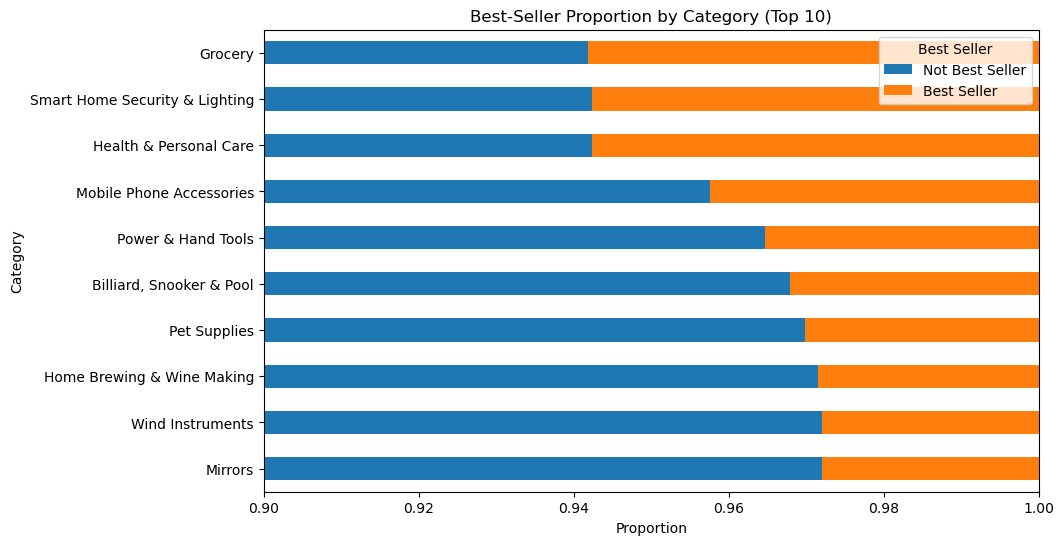

In [13]:
crosstab_prop = pd.crosstab(df["category"], df["isBestSeller"], normalize="index")
crosstab_prop.sort_values(by=True, ascending=False).head(10).plot(
    kind="barh",
    stacked=True,
    figsize=(10,6))

plt.title("Best-Seller Proportion by Category (Top 10)")
plt.xlabel("Proportion")
plt.ylabel("Category")

plt.xlim(0.9, 1) # Changin the limits might help to see better the differences between categories

plt.legend(title="Best Seller", labels=["Not Best Seller", "Best Seller"])
plt.gca().invert_yaxis()  # highest at top

plt.show()

Although some categories exhibit slightly higher proportions of best-sellers, the differences are minimal. This supports the statistical findings that product category has a significant but weak influence on best-seller status.

#### Part 2: Exploring Product Prices and Ratings Across Categories and Brands

Objective: Investigate how different product categories influence product prices.

##### 0. Preliminary Step: Remove outliers in product prices.



In [14]:
# Defining quantiles and range
q1 = df["price"].quantile(0.25)
q3 = df["price"].quantile(0.75)
iqr = q3 - q1
print(f"The price iqr =",iqr)

# defining bounds
lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr

print(f"Lower bound of price =",lower_bound) 
print(f"Upper bound of price =", upper_bound)

The price iqr = 36.0
Lower bound of price = -44.01
Upper bound of price = 99.99000000000001


In [15]:
df2 = df[(df["price"] >= lower_bound) & (df["price"] <= upper_bound)]

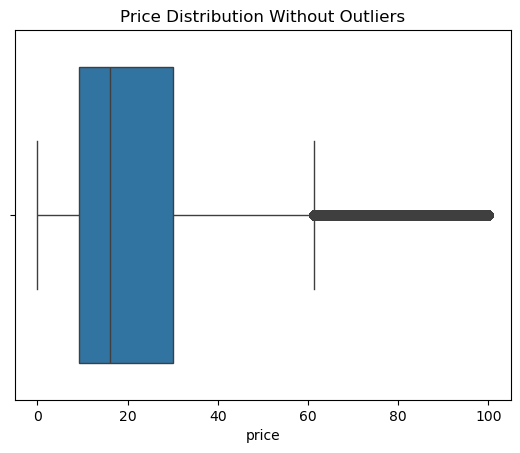

In [16]:
sns.boxplot(x=df2["price"])
plt.title("Price Distribution Without Outliers")
plt.show()

##### 1. Violin Plots:

* Use a violin plot to visualize the distribution of price across different product categories. Filter out the top 20 categories based on count for better visualization.
* Which product category tends to have the highest median price? Don't filter here by top categories.

In [18]:
## FIltering the data
top_20 = df2["category"].value_counts().head(20).index
df_top20 = df2[df2["category"].isin(top_20)]

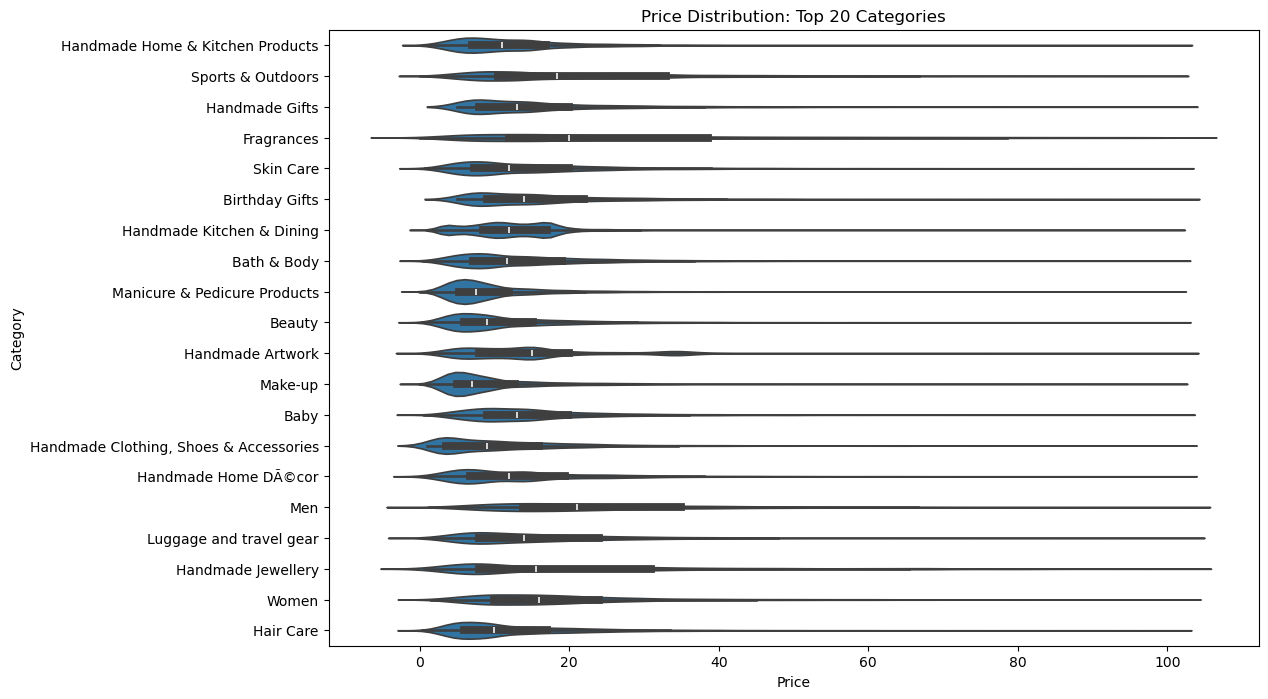

In [19]:
## Violin chart
plt.figure(figsize=(12,8))

sns.violinplot(
    data=df_top20,
    x="price",
    y="category")

plt.title("Price Distribution: Top 20 Categories")
plt.xlabel("Price")
plt.ylabel("Category")

plt.show()

In [20]:
median_prices_category = df2.groupby("category")["price"].median()
highest_median = median_prices_category.sort_values(ascending=False).head(20) # I do not know how not to filter by top categories :)
print(f"The highest median by",highest_median)

The highest median by category
Desktop PCs                74.000
Boxing Shoes               69.790
Tablets                    69.000
Graphics Cards             68.540
Motherboards               67.920
Made in Italy Handmade     64.000
Digital Frames             63.900
Streaming Clients          62.680
Golf Shoes                 62.390
Ski Helmets                61.330
Hockey Shoes               57.800
Cycling Shoes              55.990
Home Office Furniture      55.620
Skiing Poles               55.230
Computer Cases             54.990
Motorbike Batteries        54.200
Dining Room Furniture      53.000
Motorbike Drive & Gears    52.600
3D Printers                52.195
Downhill Ski Boots         51.090
Name: price, dtype: float64


The analysis of median prices across all product categories shows that Desktop PCs have the highest median price at £74.00, followed by categories such as Boxing Shoes, Tablets, and Graphics Cards.



##### 2. Bar Charts:

* Create a bar chart comparing the average price of products for the top 10 product categories (based on count).
* Which product category commands the highest average price? Don't filter here by top categories.

In [22]:
top_10 = df2["category"].value_counts().head(10).index
avg_price_10 = df2[df2["category"].isin(top_10)].groupby("category")["price"].mean().sort_values(ascending=False)

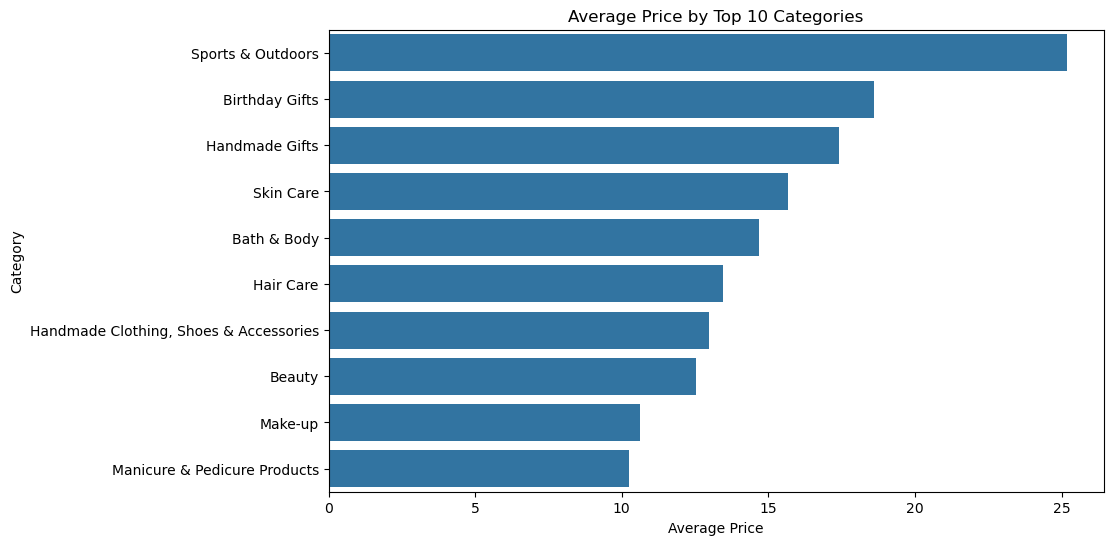

In [23]:
plt.figure(figsize=(10,6))

sns.barplot(x=avg_price_10, y=avg_price_10.index)

plt.title("Average Price by Top 10 Categories")
plt.xlabel("Average Price")
plt.ylabel("Category")

plt.show()

In [24]:
avg_price_all = df2.groupby("category")["price"].mean().sort_values(ascending=False)
avg_price_all.head(10)

category
Motherboards         68.772432
Boxing Shoes         67.417803
Desktop PCs          66.915562
Tablets              66.552971
Graphics Cards       65.103509
Digital Frames       60.745129
Streaming Clients    60.241803
Hockey Shoes         60.094796
Computer Cases       58.339884
Skiing Poles         57.867770
Name: price, dtype: float64

Avarage Price by categories counts: The bar chart shows that average prices vary across the top 10 most common product categories. Among these, Sports & Outdoors has the highest average price, indicating that products in this category tend to be more expensive compared to other high-frequency categories.

Avarage Price by category: When considering all product categories, the highest average prices are found in Motherboards (£68.77), Boxing Shoes (£67.42), and Desktop PCs (£66.92). These categories are primarily related to electronics and specialized equipment, which typically have higher production costs and market value.

##### 3. Box Plots:

* Visualize the distribution of product ratings based on their category using side-by-side box plots. Filter out the top 10 categories based on count for better visualization.
* Which category tends to receive the highest median rating from customers? Don't filter here by top categories.

In [25]:
top_10b = df2["category"].value_counts().head(10).index
df_top10 = df2[df2["category"].isin(top_10b)]

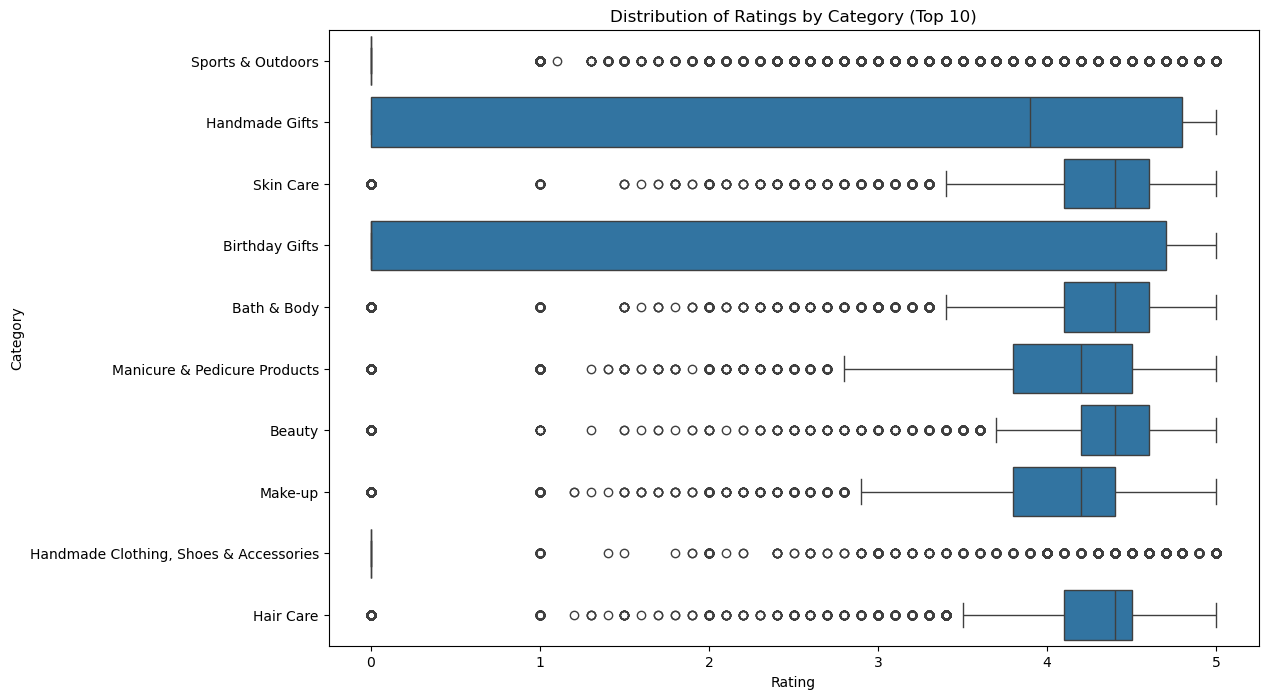

In [26]:
plt.figure(figsize=(12,8))

sns.boxplot(data=df_top10,
    x="stars",
    y="category")

plt.title("Distribution of Ratings by Category (Top 10)")
plt.xlabel("Rating")
plt.ylabel("Category")

plt.show()

In [27]:
median_ratings = df2.groupby("category")["stars"].median().sort_values(ascending=False)
median_ratings.head(10)

category
Computer Memory                 4.7
Building & Construction Toys    4.6
Office Paper Products           4.6
Luxury Food & Drink             4.6
Kids' Play Figures              4.6
Hobbies                         4.6
Beer, Wine & Spirits            4.6
Laptop Accessories              4.6
Cables & Accessories            4.5
CPUs                            4.5
Name: stars, dtype: float64

The box plots show that product ratings are consistently high across all top categories, with most median values concentrated between 4 and 5 stars.

When considering all categories, the highest median rating is observed in Computer Memory (4.7), followed by several categories such as Building & Construction Toys, Office Paper Products, and Luxury Food & Drink (around 4.6).These categories tend to receive the most favorable customer feedback, indicating high satisfaction levels.

#### Part 3: Investigating the Interplay Between Product Prices and Ratings
Objective: Analyze how product ratings (stars) correlate with product prices.

##### 1. Correlation Coefficients:

* Calculate the correlation coefficient between price and stars.
* Is there a significant correlation between product price and its rating?

In [28]:
df3 = df2[df2["stars"] > 0] ## Filtering data, cero ratings exclude
cor1 = df3["price"].corr(df3["stars"]) 
print(cor1)

0.00674450806715802


The correlation coefficient between product price and rating is 0.0067, which is extremely close to zero. This indicates that there is no meaningful relationship between price and customer ratings.



##### 2. Visualizations:

* Use a scatter plot to visualize the relationship between product rating and price. What patterns can you observe?
* Use a correlation heatmap to visualize correlations between all numerical variables.
Examine if product prices typically follow a normal distribution using a QQ plot.

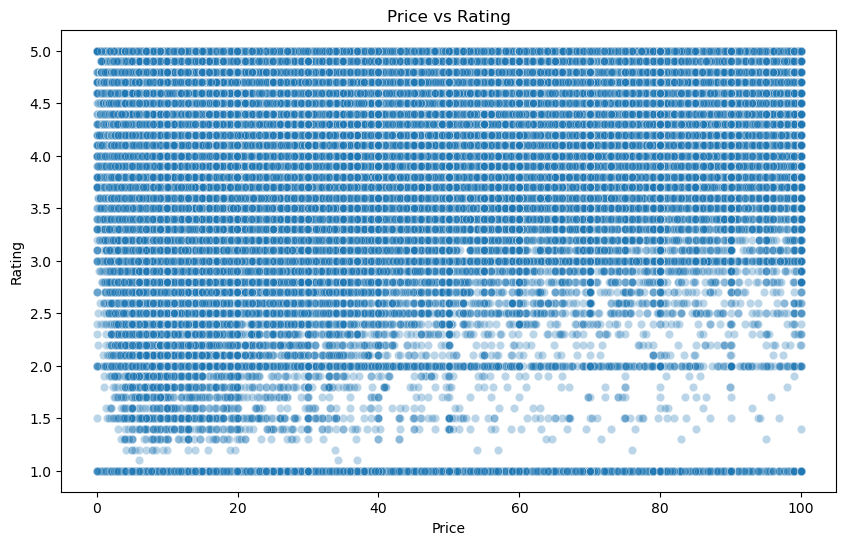

In [29]:
plt.figure(figsize=(10,6))
sns.scatterplot(data=df3, x="price", y="stars", alpha=0.3)

plt.title("Price vs Rating")
plt.xlabel("Price")
plt.ylabel("Rating")

plt.show()

The scatter plot shows a wide dispersion of ratings across all price levels, with no clear upward or downward trend

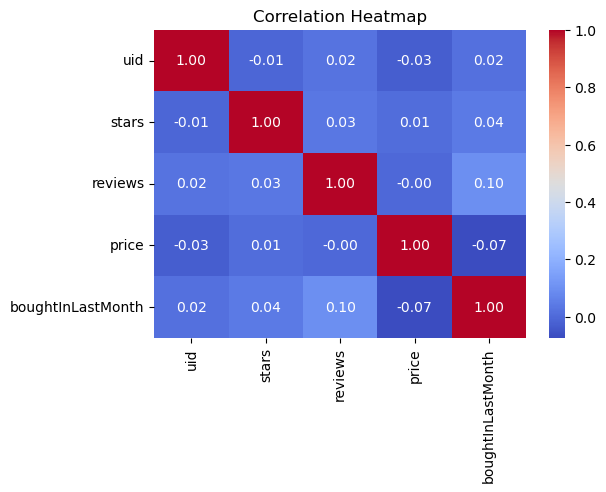

In [30]:
plt.figure(figsize=(6,4))

corr_matrix = df3.select_dtypes(include=["number"]).corr()

sns.heatmap(corr_matrix, annot=True, cmap="coolwarm", fmt=".2f")

plt.title("Correlation Heatmap")
plt.show()

The correlation heatmap shows that there are no strong linear relationships between the numerical variables in the dataset. Most correlation coefficients are very close to zero, indicating weak or negligible associations.

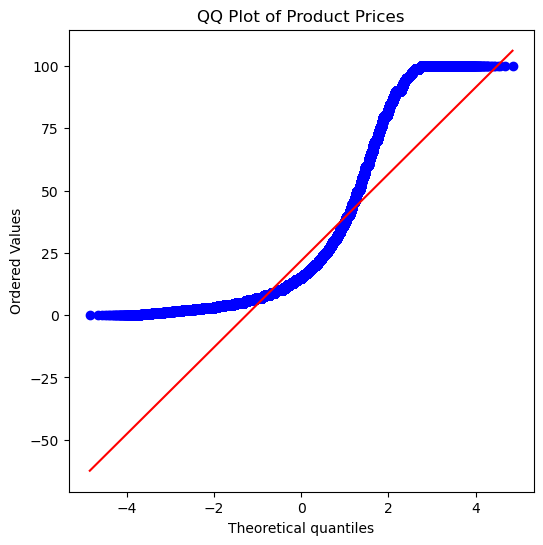

In [31]:
import scipy.stats as stats

plt.figure(figsize=(6,6))
stats.probplot(df3["price"], dist="norm", plot=plt)

plt.title("QQ Plot of Product Prices")
plt.show()

The QQ plot shows a clear deviation from the reference line, indicating that product prices do not follow a normal distribution.

# Amazon UK Product Insights – Bivariate EDA Report

## 1. Best-Seller Status by Category
* The crosstab showed that most products are not best-sellers. However, some categories have a slightly higher proportion of best-seller products than others.

* The Chi-square test showed a statistically significant relationship between category and best-seller status. However, Cramér’s V was **0.1223**, which indicates a weak association.

**Business insight:**  
Product category influences best-seller status, but only weakly. Other factors such as price, reviews, ratings, and product quality are likely also important.

## 2. Prices Across Categories
* After removing price outliers using the IQR method, most products were priced below **£100**.

* The violin plot showed that prices are mostly concentrated in lower ranges, although some categories have wider price distributions.

* The category with the highest median price was **Desktop PCs (£74.00)**.  
* The category with the highest average price was **Motherboards (£68.77)**.

**Business insight:**  
Technology and specialized product categories tend to command higher prices, while high-volume categories are generally more affordable.

## 3. Ratings Across Categories
* The boxplots showed that ratings are generally high across the top categories, usually between **4 and 5 stars**.

* The category with the highest median rating was **Computer Memory (4.7)**.

**Business insight:**  
Customer ratings are consistently positive across categories, suggesting that category alone does not strongly determine satisfaction.

## 4. Price and Rating Relationship
* The correlation between price and rating was **0.0067**, which is extremely close to zero.

* The scatter plot confirmed that there is no clear relationship between price and rating. Products at different price levels can receive similar ratings.

* The correlation heatmap also showed very weak relationships between the numerical variables.

* The QQ plot showed that product prices do not follow a normal distribution. Prices are right-skewed, with many low-priced products and fewer high-priced products.

## Final Conclusion
Overall, Amazon UK product listings show clear category differences in price and best-seller proportions, but customer ratings are not strongly connected to price. Higher-priced products do not necessarily receive better ratings.

From a business perspective, this suggests that sellers should not rely only on pricing to improve customer satisfaction. Product quality, expectations, visibility, reviews, and category strategy are likely more important for success.